In [ ]:
#The following function loads and pre-process the user-defined corpus from a specified path
#The function summarizes the steps discussed in notebook named 'Pre-processing Textual Data'
import os
import nltk
def load_corpus(path):
    #loads corpus as lsit of strings in content list
    filenames=os.listdir(path)
    documents=[]
    for i in range(len(filenames)):
        f=open(path+filenames[i])
        documents.append(f.read())
        f.close()
    return documents

In [ ]:
path="C:/Users/jasme/Downloads/imdb_text_dataset/"
documents=load_corpus(path)
documents[0]

In [ ]:
#Normalize, Tokenize, and Stop-word removal    
from nltk.corpus import *
from nltk.stem import PorterStemmer
import re
ps=PorterStemmer()
stopword=nltk.corpus.stopwords.words('english')
def preprocess(text):
    text=text.lower()
    text=re.sub(r'<.+?>',' ',text) #remove tags
    text=re.sub(r'https?://\S+|www\.\S+',' ',text) #remove URLS
    text=re.sub(r'\S@[a-zA-Z0-9]+\.[a-zA-Z]{2,}',' ',text ) #remove email ids
    text=re.sub(r'[^a-zA-Z0-9]',' ',text) #keep characters and numbers onl
    text=re.sub(r'\s+',' ',text) #remove extra white spaces
    text=[word for word in nltk.word_tokenize(text) if word not in stopword]
    text=' '.join([ps.stem(word) for word in text])
    return text
    

In [ ]:
preprocessed_docs=[]
for doc in documents:
    preprocessed_docs.append(preprocess(doc))
preprocessed_docs[0]

# Pre-processed Corpus to Feature Matrix
After pre-processing the text (documents) of the corpus, we can construct feature matrix from the pre-processed corpus and hence convert the unstructured data to structured form.

Following two types of feature matrix are broadly used for textual data:
1. Term-Document Matrix (TDM)/ Document-Term Matrix (DTM)/Bag-of-Words (BoW)
2. Term-Term Matrix (TTM)/Co-occurrence matrix 


# Variants of TDM
Depending upon how the ijth entry of the TDM matrix is filled, there are different variants of TDM matrix:
1. Binary
2. Term Frequency
3. Term Frequency with length normalization
4. Term Frequency wit maximum normalization
5. Term Frequency with log normalization
6. Term Frequency-Inverse Document Frequency

# Variant 1: Binary TDM

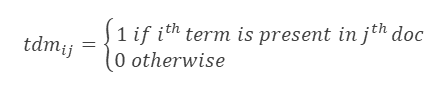

In [ ]:
#Binary TDM from Scratch
path="C:/Users/jasme/Downloads/imdb_text_dataset/"
filenames=os.listdir(path)
doc_count={} #dictionary for each document
for i in range(len(preprocessed_docs)):
    word_count={} #dictionary for words for each document
    for word in preprocessed_docs[i].split():
        if word not in word_count.keys():
            word_count[word]=1
    doc_count[filenames[i]]=word_count
doc_count


In [ ]:
#Converting dictionary to a TDM dataframe
import pandas as pd
binary_tdm_scratch=pd.DataFrame(doc_count)
binary_tdm_scratch.fillna(0,inplace=True)
binary_tdm_scratch=binary_tdm_scratch.sort_index()
binary_tdm_scratch

In [ ]:
#Binary TDM using In-built function called CountVectorizer() class of sklearn.feature_extraction.text class

#Syntax: sklearn.feature_extraction.text.CountVectorizer
#(*, input='content', encoding='utf-8', decode_error='strict', 
#strip_accents=None, lowercase=True, preprocessor=None, tokenizer=None,
#stop_words=None, token_pattern='(?u)\b\w\w+\b', ngram_range=(1, 1), 
#analyzer='word', max_df=1.0, min_df=1, max_features=None,
#vocabulary=None, binary=False, dtype=<class 'numpy.int64'>)

#For binary TDM set binary=True
from sklearn.feature_extraction.text import CountVectorizer
cv=CountVectorizer(binary=True,token_pattern='(?u)\\b\\w+\\b')
X=cv.fit_transform(preprocessed_docs) # returns a binary tdm in compressed sparse row format
print(X)

In [ ]:
#Converting X to TDM DataFrame
binary_tdm_inbuilt=pd.DataFrame(X.toarray().T,index=cv.get_feature_names(),columns=filenames)
binary_tdm_inbuilt

# Variant 2: Term Frequency TDM

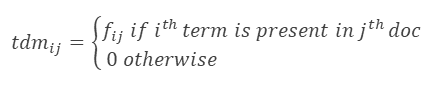

In [ ]:
# Term frequency TDM from scratch
path="C:/Users/jasme/Downloads/imdb_text_dataset/"
filenames=os.listdir(path)
doc_count1={} #dictionary for each document
for i in range(len(preprocessed_docs)):
    word_count1={} #dictionary for words for each document
    for word in preprocessed_docs[i].split():
        if word not in word_count1.keys():
            word_count1[word]=0
        word_count1[word]+=1
    doc_count1[filenames[i]]=word_count1
doc_count1


In [ ]:
#Converting dictionary to term frequency TDM dataframe
tdm_tf_scratch=pd.DataFrame(doc_count1)
tdm_tf_scratch.fillna(0,inplace=True)
tdm_tf_scratch=tdm_tf_scratch.sort_index()
tdm_tf_scratch

In [ ]:
# Term frequency TDM using CountVectorizer of Sklearn library
from sklearn.feature_extraction.text import CountVectorizer
cv1=CountVectorizer(token_pattern='(?u)\\b\\w+\\b')
Y=cv1.fit_transform(preprocessed_docs) # returns a term frequency tdm in compressed sparse row (csr) format 
print(Y)

In [ ]:
# Converting csr format to dataframe
tdm_tf_inbuilt=pd.DataFrame(Y.toarray().T,index=cv1.get_feature_names(),columns=filenames)
tdm_tf_inbuilt